In [1]:
import sys
sys.path.append("../scripts")

import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from data_pipeline import MODELS_DIR, FIGURES_DIR, get_train_val_test_split

Loads the data and the saved models all three are tested on the same test set

In [3]:
X_train, X_val, X_test, y_train, y_val, y_test = get_train_val_test_split()

models = {
    "Naive Bayes":   joblib.load(MODELS_DIR / "naive_bayes_best_model.joblib"),
    "KNN":           joblib.load(MODELS_DIR / "knn_best_model.joblib"),
    "Decision Tree": joblib.load(MODELS_DIR / "decision_tree_best_model.joblib"),
}

This is the overall results scored with accuracy and macro F1 

               Accuracy  Macro F1
Model                            
Naive Bayes       0.716     0.718
KNN               0.969     0.969
Decision Tree     0.802     0.799


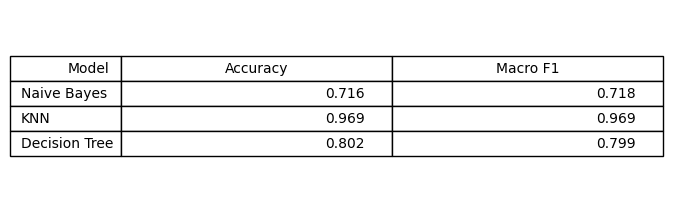

In [23]:

predictions = {}
results = []

for name in models:

    model = models[name]
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": f1
    })


results = pd.DataFrame(results).set_index("Model")
print(results.round(3))


fig, ax = plt.subplots(figsize=(7, 2.5))
ax.axis("off")

table = ax.table(
    cellText=results.round(3).values,
    rowLabels=results.index,
    colLabels=results.columns,
    loc="center"
)
table.add_cell(0, -1, text="Model", width=0.2, height=table[0,0].get_height())
table.scale(1, 1.5)
plt.savefig(FIGURES_DIR / "overall_results.png", bbox_inches="tight", dpi=150)
plt.show()


per-class F1 table for each of the classes for all models needed since overall scores can often hide weakness 

        Naive Bayes    KNN  Decision Tree
c-CS-m        0.476  0.930          0.682
c-CS-s        0.545  1.000          0.718
c-SC-m        0.952  0.952          0.913
c-SC-s        0.703  0.952          0.857
t-CS-m        0.596  1.000          0.800
t-CS-s        0.759  0.914          0.706
t-SC-m        0.762  1.000          0.905
t-SC-s        0.952  1.000          0.811


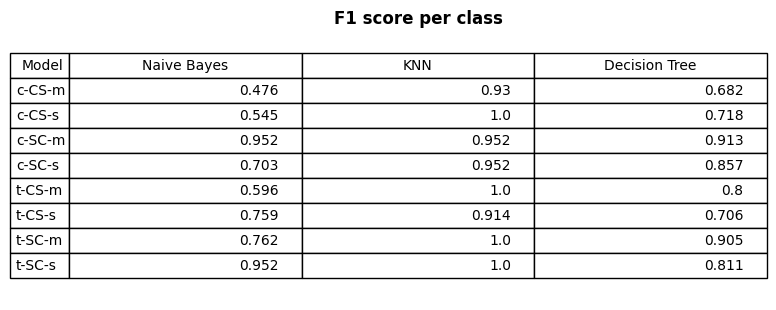

In [29]:
classes = sorted(y_test.unique())

class_scores = {}

for name in predictions:

    y_pred = predictions[name]

    f1 = f1_score(y_test, y_pred, average=None, labels=classes)

    class_scores[name] = f1

per_class = pd.DataFrame(class_scores, index=classes)

print(per_class.round(3))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.axis("off")

table = ax.table(
    cellText=per_class.round(3).values,
    rowLabels=per_class.index,
    colLabels=per_class.columns,
    loc="center"
)
table.add_cell(0, -1, text="Model", width=0.2, height=table[0,0].get_height())
table.scale(1, 1.5)
ax.set_title("F1 score per class", fontweight="bold", pad=5)
plt.savefig(FIGURES_DIR / "per_class_results.png", bbox_inches="tight", dpi=150)
plt.show()


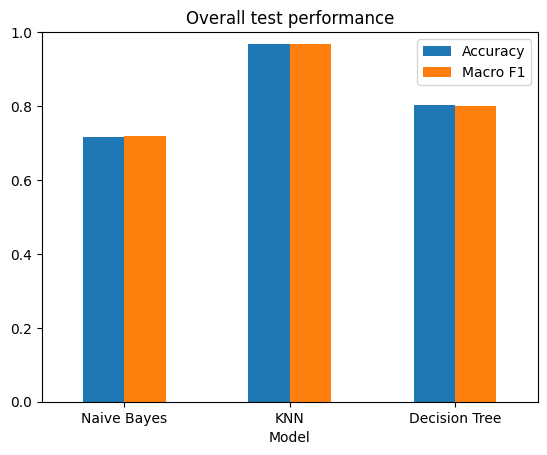

In [6]:
results.plot.bar(rot=0, ylim=(0, 1), title="Overall test performance")
plt.savefig(FIGURES_DIR / "compare_overall.png", dpi=150, bbox_inches="tight")
plt.show()

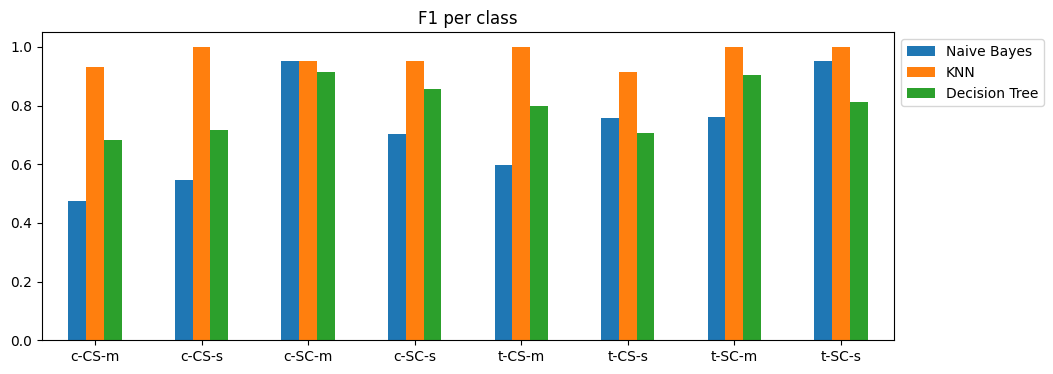

In [9]:
per_class.plot.bar(rot=0, ylim=(0, 1.05), figsize=(11, 4), title="F1 per class")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.savefig(FIGURES_DIR / "compare_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

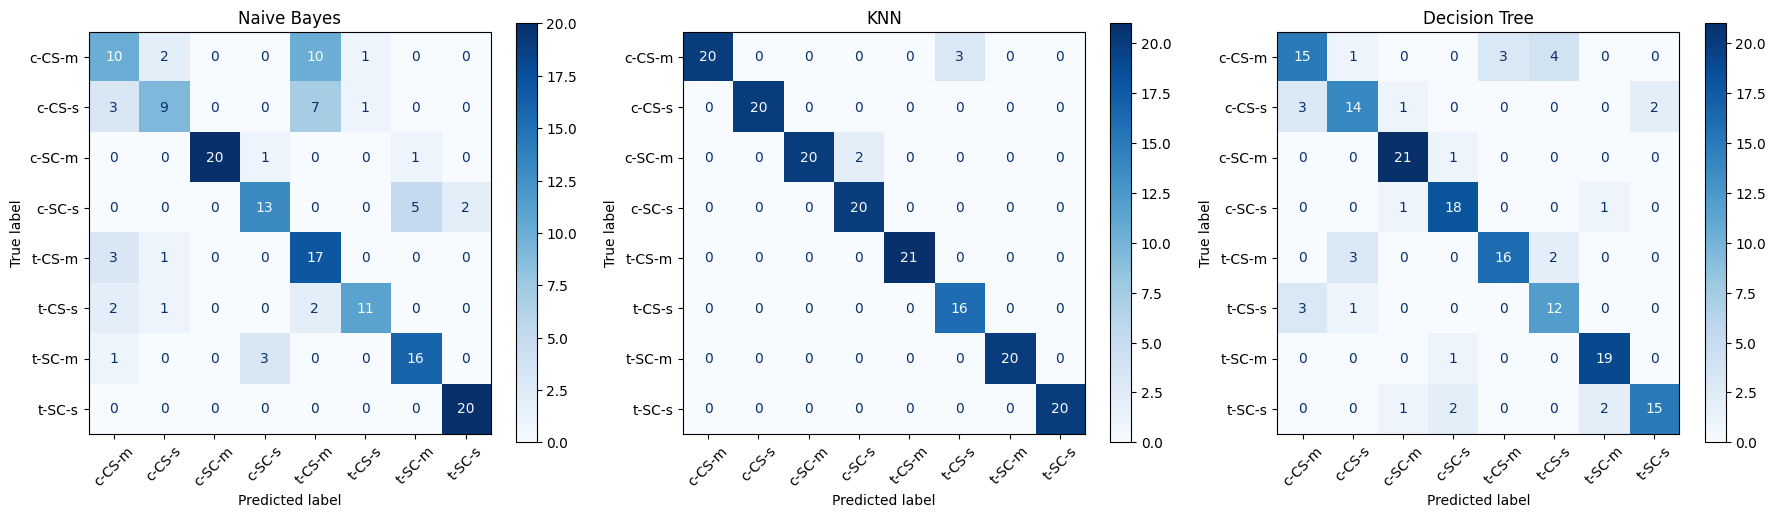

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

names = list(predictions.keys())

for i in range(3):

    name = names[i]
    y_pred = predictions[name]

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=axes[i],
        cmap="Blues",
        xticks_rotation=45
    )

    axes[i].set_title(name)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "compare_confusion.png", dpi=150)
plt.show()